# 23 Where in the body does the ST-GCN look? Joint ablation on the trained models

**Why this notebook.** Notebook 22 found that the LSTM, Transformer and ST-TR add little beyond another ST-GCN seed, which
fits the idea that the models share the same blind spots because of what the body keypoints contain. This notebook
asks a narrower question that can be answered without training anything: **which joints does the trained ST-GCN rely on,
and do the shots it confuses rely on the racket arm more than the other shots do?**

**Method.** The two stage 1 control models (ST-GCN with velocity, tuning seeds 77 and 88) are loaded and run on the
validation clips with groups of joints removed at test time. A removed joint has its confidence set to zero and its
position replaced by the mean position of the joints that remain, so it carries no information; bone and velocity
channels are recomputed from the masked positions. The racket side of each clip is the wrist that moves more
(confidence weighted path length), a heuristic that is checked in the smoke test.

Removing joints puts the input outside what the model saw in training, so a drop in accuracy alone does not show reliance
on those joints. Every group is therefore compared with **random joint sets of the same size** (20 draws per clip, any
joints). The quantity reported is the *selectivity*: accuracy lost by removing the named joints minus the accuracy lost by
removing the same number of random ones.

| group | joints |
|---|---|
| `racket_arm` | racket-side shoulder, elbow, wrist (3) |
| `racket_forearm` | racket-side elbow, wrist (2) |
| `racket_wrist` | racket-side wrist (1) |
| `off_arm` | the other shoulder, elbow, wrist (3) |
| `head` | nose, eyes, ears (5) |
| `lower_body` | hips, knees, ankles (6) |

**Decision rule, fixed before running.** The shots the model confuses are the classes in the four most confused class
pairs of the control models on validation. An arm focused pathway is justified if the racket-arm selectivity is at least
**5 points higher on clips of those classes than on the other clips**, and the 95% bootstrap interval of that difference
(clips resampled within each group) excludes zero. If not, the confusions do not depend on the arm more than other shots
do, and the missing information is not something an arm focused pathway would be able to recover.

**What a pass does and does not mean.** Ablation measures what the model uses, not what it lacks. A pass says the
decision between confusable shots sits in fine arm motion, which is where a dedicated pathway could help; it does not say
the ST-GCN uses that information badly. It would justify building and testing the pathway, nothing more. Validation only,
no test data, no clip duration.

Logs to `BadmintonPoseAnalysis/experiments/joint_ablation`.

In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from clearml import Task
from sklearn.metrics import confusion_matrix

REPO = os.environ.get("BADMINTON_REPO", "/workspace/badminton-honours-project")
DATA = os.environ.get("BADMINTON_DATA", "/workspace/data")
OUTPUTS = os.environ.get("BADMINTON_OUTPUTS", "/workspace/outputs")
sys.path.insert(0, REPO)
import dataset as ds
from models import stgcn as stgcn_model
import training as tr

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__, device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

2.1.0+cu118 cuda NVIDIA GeForce RTX 4090


In [2]:
PROJECT = "BadmintonPoseAnalysis/experiments/joint_ablation"
KEYPOINTS = f"{DATA}/keypoints_interp"
STAGE1_OUT = f"{OUTPUTS}/experiments/model5_stage1_graph"
OUT = f"{OUTPUTS}/experiments/joint_ablation"
os.makedirs(OUT, exist_ok=True)

SEEDS = [77, 88]
NORMALISATION, USE_COURT, USE_VELOCITY = "body", True, True
MIN_CLASS_FRAMES = 5
N_DRAWS, N_BOOT, N_PAIRS, MIN_MARGIN = 20, 2000, 4, 0.05
BATCH = 128

with open(f"{REPO}/configs/model5_stage1.json") as f:
    VEL_SCALE = json.load(f)["velocity_scale"]
rng = np.random.RandomState(0)
torch.manual_seed(0)

J = {n: i for i, n in enumerate(ds.JOINT_NAMES)}
HEAD = [J[n] for n in ("nose", "l_eye", "r_eye", "l_ear", "r_ear")]
LOWER = [J[n] for n in ("l_hip", "r_hip", "l_knee", "r_knee", "l_ankle", "r_ankle")]
SIDE = {"l": [J["l_shoulder"], J["l_elbow"], J["l_wrist"]], "r": [J["r_shoulder"], J["r_elbow"], J["r_wrist"]]}
CONDITIONS = ["racket_arm", "racket_forearm", "racket_wrist", "off_arm", "head", "lower_body"]

In [3]:
manifest = ds.load_filtered_manifest(f"{DATA}/split_manifest.csv", f"{DATA}/extraction_log.csv",
                                     f"{DATA}/keypoints_interp_log.csv", MIN_CLASS_FRAMES)
class_names = sorted(manifest["class_name"].unique())
class_to_id = {c: i for i, c in enumerate(class_names)}
K = len(class_names)
split_hash = open(f"{DATA}/split_manifest.sha256").read().split()[0]

val = manifest[manifest["split"] == "val"].sort_values("filepath").reset_index(drop=True)
dataset = ds.BadmintonPoseDataset(val, KEYPOINTS, class_to_id, "none", NORMALISATION)     # clean clips, no augmentation
items = [dataset[i] for i in range(len(dataset))]
KP = torch.stack([it["keypoints"] for it in items]).float().to(device)       # (N, T, 17, 3)
COURT = torch.stack([it["court"] for it in items]).float().to(device)        # (N, T, 2)
LABELS = np.array([int(it["label"]) for it in items])
PATHS = np.array([it["filepath"] for it in items])
N = len(LABELS)
PARENT = torch.as_tensor(ds.PARENT, dtype=torch.long, device=device)
print(f"{N} validation clips, {KP.shape[1]} frames, {K} classes")

# racket side: the wrist with the larger confidence weighted path length
xy, conf = KP[..., :2], KP[..., 2]
step = (xy[:, 1:] - xy[:, :-1]).norm(dim=-1)
w = torch.minimum(conf[:, 1:], conf[:, :-1])
speed = (step * w).sum(1) / w.sum(1).clamp(min=1e-6)                           # (N, 17)
RACKET_RIGHT = (speed[:, J["r_wrist"]] > speed[:, J["l_wrist"]]).cpu().numpy()
print(f"racket side: right in {RACKET_RIGHT.mean():.1%} of validation clips")


def group_masks():
    """(N, 17) boolean mask per condition: True where the joint is removed."""
    masks = {c: np.zeros((N, ds.NUM_JOINTS), dtype=bool) for c in CONDITIONS}
    for i in range(N):
        racket, off = SIDE["r" if RACKET_RIGHT[i] else "l"], SIDE["l" if RACKET_RIGHT[i] else "r"]
        masks["racket_arm"][i, racket] = True
        masks["racket_forearm"][i, racket[1:]] = True
        masks["racket_wrist"][i, racket[2:]] = True
        masks["off_arm"][i, off] = True
    masks["head"][:, HEAD] = True
    masks["lower_body"][:, LOWER] = True
    return {c: torch.as_tensor(m, device=device) for c, m in masks.items()}


MASKS = group_masks()
SIZES = {c: int(MASKS[c][0].sum()) for c in CONDITIONS}
print("group sizes:", SIZES)


def apply_mask(mask, idx):
    """Batch dict for clips idx with the joints in mask (n, 17) removed; bone is recomputed from the masked positions."""
    kp, court = KP[idx], COURT[idx]
    keep = (~mask)[:, None, :, None].float()
    mean_xy = (kp[..., :2] * keep).sum(2, keepdim=True) / keep.sum(2, keepdim=True).clamp(min=1.0)
    new_xy = torch.where(mask[:, None, :, None], mean_xy.expand_as(kp[..., :2]), kp[..., :2])
    new_conf = torch.where(mask[:, None, :], torch.zeros_like(kp[..., 2]), kp[..., 2])
    bone = new_xy - new_xy[:, :, PARENT, :]
    return {"keypoints": torch.cat([new_xy, new_conf[..., None]], dim=-1), "bone": bone, "court": court}


FORWARD = stgcn_model.make_forward(USE_COURT, USE_VELOCITY, VEL_SCALE)


@torch.no_grad()
def predict(model, mask):
    out = []
    for start in range(0, N, BATCH):
        idx = torch.arange(start, min(start + BATCH, N), device=device)
        out.append(FORWARD(model, apply_mask(mask[idx], idx), device).argmax(1).cpu().numpy())
    return np.concatenate(out)


def load_model(seed):
    run = f"model5s1_control_s{seed}"
    model = stgcn_model.build_stgcn(stgcn_model.n_channels(USE_COURT, USE_VELOCITY), K).to(device)
    model.load_state_dict(torch.load(f"{STAGE1_OUT}/{run}/{run}.pt", map_location=device))
    return model.eval()


def _random_membership(k):
    chosen = np.argsort(rng.rand(N, ds.NUM_JOINTS), axis=1)[:, :k]
    m = np.zeros((N, ds.NUM_JOINTS), dtype=bool)
    m[np.arange(N)[:, None], chosen] = True
    return m

manual review: dropped 4 clips
short clip rule: dropped 4 train clips with fewer than 5 real frames
7810 clips remain (train 6247, test 782, val 781)
781 validation clips, 30 frames, 18 classes
racket side: right in 66.6% of validation clips
group sizes: {'racket_arm': 3, 'racket_forearm': 2, 'racket_wrist': 1, 'off_arm': 3, 'head': 5, 'lower_body': 6}


## Smoke test

The unmasked models must reproduce the validation predictions saved when they were trained; a mask that removes nothing
must change nothing; a removed joint must really carry no information; and the racket-side rule should pick the
hand that actually moves.

In [5]:
none = torch.zeros((N, ds.NUM_JOINTS), dtype=torch.bool, device=device)
idx = torch.arange(8, device=device)
same = apply_mask(none[idx], idx)
assert torch.equal(same["keypoints"], KP[idx]) and torch.allclose(same["bone"], torch.as_tensor(
    np.stack([ds.compute_bone(KP[i, ..., :2].cpu().numpy()) for i in range(8)])).to(device), atol=1e-6), "empty mask changed the input"

part = apply_mask(MASKS["racket_arm"][idx], idx)
for r, i in enumerate(range(8)):
    gone = MASKS["racket_arm"][i].nonzero().flatten().tolist()
    assert len(gone) == 3 and (part["keypoints"][r][:, gone, 2] == 0).all()
    rest = [j for j in range(ds.NUM_JOINTS) if j not in gone]
    assert torch.allclose(part["keypoints"][r][:, gone, :2], KP[i][:, rest, :2].mean(1, keepdim=True).expand(-1, 3, -1), atol=1e-5)
    assert torch.equal(part["keypoints"][r][:, rest], KP[i][:, rest]), "joints outside the mask were changed"

baseline, saved_acc = {}, {}
for seed in SEEDS:
    model = load_model(seed)
    baseline[seed] = predict(model, none)
    saved = pd.read_csv(f"{STAGE1_OUT}/model5s1_control_s{seed}/model5s1_control_s{seed}_predictions.csv")
    saved = saved[saved["split"] == "val"].sort_values("filepath").reset_index(drop=True)
    assert (saved["filepath"].to_numpy() == PATHS).all()
    saved_pred = saved["pred"].map(class_to_id).to_numpy()
    agree = (saved_pred == baseline[seed]).mean()
    print(f"seed {seed}: val top1 {np.mean(baseline[seed] == LABELS):.4f}, saved {np.mean(saved_pred == LABELS):.4f}, "
          f"predictions identical on {agree:.1%} of clips")
    assert agree > 0.99, "the loaded checkpoint does not reproduce the saved predictions"
    saved_acc[seed] = float(np.mean(saved_pred == LABELS))
    del model

wrist_gap = (speed[:, J["r_wrist"]] - speed[:, J["l_wrist"]]).abs().cpu().numpy()
faster = speed[:, [J["l_wrist"], J["r_wrist"]]].max(1).values.cpu().numpy()
print(f"racket side rule: median wrist speed gap {np.median(wrist_gap):.4f}, "
      f"clips where the two wrists differ by under 10%: {(wrist_gap < 0.1 * faster).mean():.1%}")
print("smoke test passed")

seed 77: val top1 0.7644, saved 0.7644, predictions identical on 100.0% of clips
seed 88: val top1 0.7708, saved 0.7708, predictions identical on 100.0% of clips
racket side rule: median wrist speed gap 0.0105, clips where the two wrists differ by under 10%: 22.9%
smoke test passed


## Ablation

For each model and group: accuracy with the named joints removed, and with random joint sets of the same size (20 draws).
Per clip, the loss is `correct without ablation − correct with ablation`, so +1 means the ablation broke a clip
that was right and −1 means it fixed one that was wrong.

In [6]:
delta, delta_rand, rand_overall = {}, {}, {}
for seed in SEEDS:
    model = load_model(seed)
    c0 = (baseline[seed] == LABELS).astype(np.float32)
    for cond in CONDITIONS:
        delta[(seed, cond)] = c0 - (predict(model, MASKS[cond]) == LABELS)
        draws = []
        for _ in range(N_DRAWS):
            mask = torch.as_tensor(_random_membership(SIZES[cond]), device=device)
            draws.append(c0 - (predict(model, mask) == LABELS))
        draws = np.stack(draws)                                    # (draws, N)
        delta_rand[(seed, cond)] = draws.mean(0)
        rand_overall[(seed, cond)] = draws.mean(1)                 # accuracy lost per draw
    del model
    print(f"seed {seed} done")

# seed averaged per clip loss, and per clip selectivity (named joints minus random joints of the same size)
D = {c: np.mean([delta[(s, c)] for s in SEEDS], axis=0) for c in CONDITIONS}
R = {c: np.mean([delta_rand[(s, c)] for s in SEEDS], axis=0) for c in CONDITIONS}
S = {c: D[c] - R[c] for c in CONDITIONS}


def boot_ci(values):
    b = [values[rng.randint(0, len(values), len(values))].mean() for _ in range(N_BOOT)]
    return np.percentile(b, [2.5, 97.5])


rows = []
for c in CONDITIONS:
    lo, hi = boot_ci(S[c])
    per_draw = np.concatenate([rand_overall[(s, c)] for s in SEEDS])
    rows.append({"group": c, "joints": SIZES[c], "accuracy lost, named (pts)": 100 * D[c].mean(),
                 "accuracy lost, random same size (pts)": 100 * R[c].mean(), "random draw sd (pts)": 100 * per_draw.std(),
                 "selectivity (pts)": 100 * S[c].mean(), "95% CI": f"[{100 * lo:+.1f}, {100 * hi:+.1f}]"})
overall = pd.DataFrame(rows)
overall_show = overall.round({"accuracy lost, named (pts)": 1, "accuracy lost, random same size (pts)": 1,
                              "random draw sd (pts)": 1, "selectivity (pts)": 1})
print(f"unmasked validation top1 (mean of seeds): {100 * np.mean(list(saved_acc.values())):.1f}")
overall_show

seed 77 done
seed 88 done
unmasked validation top1 (mean of seeds): 76.8


,group,joints,"accuracy lost, named (pts)","accuracy lost, random same size (pts)",random draw sd (pts),selectivity (pts),95% CI
0,racket_arm,3,24.8,35.5,3.9,-10.7,"[-12.8, -8.4]"
1,racket_forearm,2,8.0,23.7,3.1,-15.6,"[-17.6, -13.8]"
2,racket_wrist,1,4.8,11.5,1.9,-6.7,"[-8.1, -5.1]"
3,off_arm,3,25.7,35.9,4.1,-10.2,"[-12.6, -7.8]"
4,head,5,64.1,52.0,2.4,12.1,"[+10.0, +14.1]"
5,lower_body,6,68.8,57.0,1.2,11.8,"[+10.3, +13.3]"


In [7]:
# the shots the model confuses: the four most confused class pairs of the two control models on validation
cm = sum(confusion_matrix(LABELS, baseline[s], labels=list(range(K))) for s in SEEDS)
pair_score = {(i, j): int(cm[i, j] + cm[j, i]) for i in range(K) for j in range(i + 1, K)}
top_pairs = sorted(pair_score, key=pair_score.get, reverse=True)[:N_PAIRS]
short = [c.split("_", 1)[-1] for c in class_names]
print("most confused pairs (errors in either direction, both seeds):")
for i, j in top_pairs:
    print(f"  {short[i]} / {short[j]}: {pair_score[(i, j)]}")
confusable = sorted({k for p in top_pairs for k in p})
is_conf = np.isin(LABELS, confusable)
print(f"confusable classes: {[short[k] for k in confusable]} ({is_conf.sum()} validation clips; {(~is_conf).sum()} other clips)")

rows = []
for c in CONDITIONS:
    a, b = S[c][is_conf], S[c][~is_conf]
    diffs = [rng.choice(a, len(a)).mean() - rng.choice(b, len(b)).mean() for _ in range(N_BOOT)]
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    rows.append({"group": c, "selectivity, confusable classes (pts)": 100 * a.mean(), "selectivity, other classes (pts)": 100 * b.mean(),
                 "difference (pts)": 100 * (a.mean() - b.mean()), "ci_lo": lo, "ci_hi": hi})
split_table = pd.DataFrame(rows)
split_show = split_table.assign(**{"95% CI": [f"[{100 * a:+.1f}, {100 * b:+.1f}]" for a, b in zip(split_table["ci_lo"], split_table["ci_hi"])]}
                                ).drop(columns=["ci_lo", "ci_hi"]).round(1)
split_show

most confused pairs (errors in either direction, both seeds):
  Lift / Push Shot: 24
  Cut / Smash: 24
  Lift / Flat Shot: 22
  Block / Drop Shot: 20
confusable classes: ['Lift', 'Block', 'Drop Shot', 'Push Shot', 'Cut', 'Smash', 'Flat Shot'] (402 validation clips; 379 other clips)


,group,"selectivity, confusable classes (pts)","selectivity, other classes (pts)",difference (pts),95% CI
0,racket_arm,-8.5,-13.0,4.4,"[+0.3, +8.9]"
1,racket_forearm,-12.9,-18.6,5.7,"[+2.0, +9.1]"
2,racket_wrist,-6.5,-6.8,0.3,"[-2.6, +3.2]"
3,off_arm,-3.2,-17.6,14.4,"[+9.9, +18.9]"
4,head,24.4,-0.9,25.4,"[+21.7, +29.0]"
5,lower_body,11.0,12.7,-1.7,"[-4.4, +1.2]"


In [8]:
# per class accuracy lost beyond random, for every group
per_class = pd.DataFrame({c: [100 * S[c][LABELS == k].mean() for k in range(K)] for c in CONDITIONS}, index=short)
per_class["clips"] = [int((LABELS == k).sum()) for k in range(K)]
per_class["confusable"] = [k in confusable for k in range(K)]
per_class.round(1)

,racket_arm,racket_forearm,racket_wrist,off_arm,head,lower_body,clips,confusable
Short Serve,-14.0,-32.5,-13.8,-23.2,15.0,9.2,88,False
Cross Court Flight,-6.8,-11.2,-11.2,5.1,2.6,1.3,17,False
Lift,-13.9,-4.1,0.1,-12.6,44.3,12.4,76,True
Tap Smash,-6.6,-5.7,-2.7,-7.7,6.8,0.9,11,False
Block,3.8,-27.6,-11.6,2.0,20.5,14.6,32,True
Drop Shot,-0.6,-17.4,-6.6,14.8,32.2,-2.1,81,True
Push Shot,6.9,-16.7,-11.1,9.9,9.4,6.4,40,True
Transitional Slice,8.5,-18.3,-4.6,16.9,14.6,10.2,12,False
Cut,-10.0,-12.4,-13.8,-10.0,-3.0,7.4,58,True
Rush Shot,11.1,-36.4,-10.5,43.0,17.3,7.3,11,False


racket arm selectivity: confusable classes -8.5, other classes -13.0; difference +4.4 points [+0.3, +8.9]
rule (difference >= 5 points and interval above zero): NOT PASSED, the confusable shots do not lean on the racket arm more than the others do


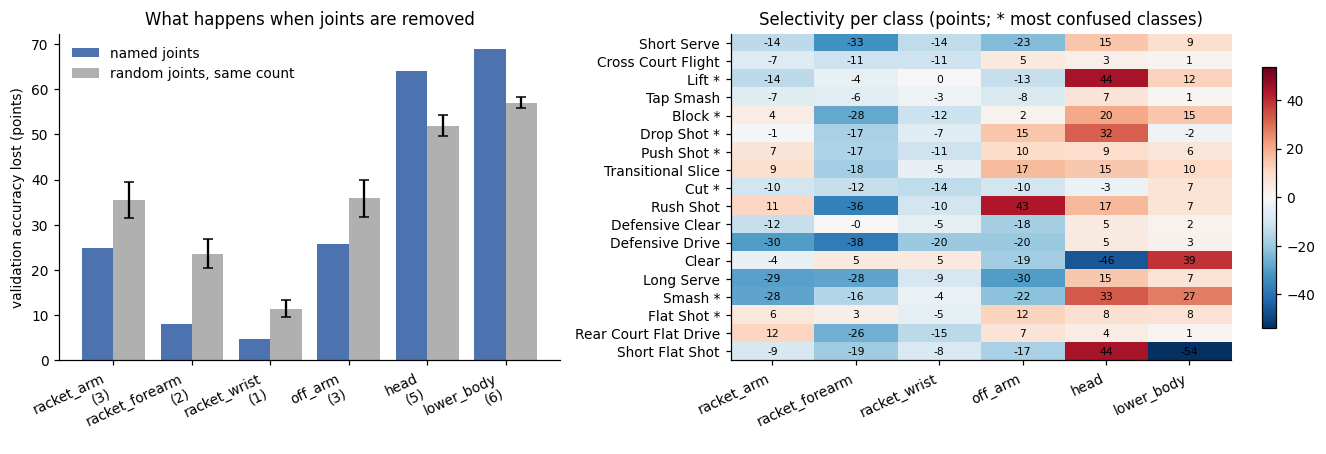

In [9]:
row = split_table[split_table["group"] == "racket_arm"].iloc[0]
justified = bool(row["difference (pts)"] >= 100 * MIN_MARGIN and row["ci_lo"] > 0)
print(f"racket arm selectivity: confusable classes {row['selectivity, confusable classes (pts)']:+.1f}, other classes "
      f"{row['selectivity, other classes (pts)']:+.1f}; difference {row['difference (pts)']:+.1f} points "
      f"[{100 * row['ci_lo']:+.1f}, {100 * row['ci_hi']:+.1f}]")
print("rule (difference >= 5 points and interval above zero):",
      "PASSED, an arm focused pathway is worth building and testing" if justified
      else "NOT PASSED, the confusable shots do not lean on the racket arm more than the others do")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
x = np.arange(len(CONDITIONS))
ax.bar(x - 0.2, overall["accuracy lost, named (pts)"], 0.4, label="named joints", color="#4c72b0")
ax.bar(x + 0.2, overall["accuracy lost, random same size (pts)"], 0.4, yerr=overall["random draw sd (pts)"], capsize=3,
       label="random joints, same count", color="#b0b0b0")
ax.set_xticks(x, [f"{c}\n({SIZES[c]})" for c in CONDITIONS], rotation=25, ha="right")
ax.set_ylabel("validation accuracy lost (points)")
ax.set_title("What happens when joints are removed")
ax.legend(frameon=False)
ax = axes[1]
mat = per_class[CONDITIONS].to_numpy()
lim = np.abs(mat).max()
im = ax.imshow(mat, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(CONDITIONS)), CONDITIONS, rotation=25, ha="right")
ax.set_yticks(range(K), [f"{n} *" if k in confusable else n for k, n in enumerate(short)])
for (i, j), v in np.ndenumerate(mat):
    ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7)
ax.set_title("Selectivity per class (points; * most confused classes)")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
plt.show()

In [10]:
task = Task.init(project_name=PROJECT, task_name="joint_ablation", task_type=Task.TaskTypes.qc,
                 tags=["joint_ablation", "diagnostic"], reuse_last_task_id=False, auto_connect_frameworks={"matplotlib": False})
log = task.get_logger()
task.connect({"seeds": SEEDS, "checkpoints": "model5_stage1_graph control", "draws": N_DRAWS, "bootstrap": N_BOOT,
              "confused_pairs": N_PAIRS, "split_sha256": split_hash, "evaluated_splits": ["val"],
              "rule": {"min_margin": MIN_MARGIN, "interval_above_zero": True}, "mask": "confidence 0, position = mean of remaining joints"})
log.report_table("overall", "val", iteration=0, table_plot=overall_show)
log.report_table("racket arm and the others, confusable vs other classes", "val", iteration=0, table_plot=split_show)
log.report_table("per class selectivity", "val", iteration=0, table_plot=per_class.round(1).reset_index().rename(columns={"index": "class"}))
log.report_matplotlib_figure("joint ablation", "val", figure=fig, iteration=0, report_interactive=False)

decision = {"experiment": "joint_ablation", "arm_pathway_justified": justified,
            "confusable_classes": [short[k] for k in confusable],
            "racket_arm_selectivity_confusable_pts": round(float(row["selectivity, confusable classes (pts)"]), 2),
            "racket_arm_selectivity_other_pts": round(float(row["selectivity, other classes (pts)"]), 2),
            "difference_pts": round(float(row["difference (pts)"]), 2),
            "ci_pts": [round(100 * float(row["ci_lo"]), 2), round(100 * float(row["ci_hi"]), 2)],
            "rule": {"min_margin_points": 100 * MIN_MARGIN, "interval_above_zero": True}}
with open(f"{REPO}/configs/joint_ablation.json", "w") as f:
    json.dump(decision, f, indent=2)
task.upload_artifact("decision", artifact_object=f"{REPO}/configs/joint_ablation.json")
task.close()
decision

ClearML Task: created new task id=9747defd3b4c461ab815381f6b32e358
2026-10-08 01:26:37,830 - clearml.Repository Detection - WARNING - Failed accessing the jupyter server(s): []
ClearML results page: https://app.clear.ml/projects/6a32c2dbac0e40b399f2676c31b91d2c/tasks/9747defd3b4c461ab815381f6b32e358/output/log


{'experiment': 'joint_ablation',
 'arm_pathway_justified': False,
 'confusable_classes': ['Lift',
  'Block',
  'Drop Shot',
  'Push Shot',
  'Cut',
  'Smash',
  'Flat Shot'],
 'racket_arm_selectivity_confusable_pts': -8.54,
 'racket_arm_selectivity_other_pts': -12.96,
 'difference_pts': 4.42,
 'ci_pts': [0.28, 8.9],
 'rule': {'min_margin_points': 5.0, 'interval_above_zero': True}}

## Reading the result

- **Overall table.** A group whose removal costs clearly more than random joints of the same count (beyond the random-draw
  spread) is a group the model relies on. A group that costs the same as random joints is one the model treats
  like any other. Single joints and small groups are compared only with random sets of their own size, so the
  columns can be read across groups without correcting for how many joints were removed.
- **Rule passes.** The shots the ST-GCN confuses are the ones whose label depends most on the racket arm. The natural
  next experiment is a pathway that models the racket arm at finer detail (more temporal resolution, wrist and
  forearm geometry), added to the ST-GCN and compared with it, with the pathway removed as the ablation.
- **Rule fails.** The confusions do not hinge on the arm any more than the other shots do, so adding capacity there
  has no evidence behind it. Together with notebook 22 that points to the ceiling being set by the input (body
  keypoints without racket or shuttle), which is a finding to report in its own right.
- **Caveats.** Masking moves the input off the training distribution, which is why the random sets of equal size are the
  baseline. The racket side is inferred from wrist motion and is wrong for some clips. Validation has been used at every
  stage, and the interval treats clips as independent, although clips from the same match are not.